#### 이진분류

In [98]:
import torch
import matplotlib.pyplot as plt

#### Step 1. 데이터 생성

In [99]:
N = 20

random0 = torch.randn(int(N/2), 1)
random5 = torch.randn(int(N/2), 1)+5

# data
class1_data = torch.hstack([random0,random5])
class2_data = torch.hstack([random5,random0])

# label
class1_label = torch.ones(int(N/2),1)
class2_label = torch.zeros(int(N/2),1)

x = torch.vstack([class1_data, class2_data])
y = torch.vstack([class1_label, class2_label])


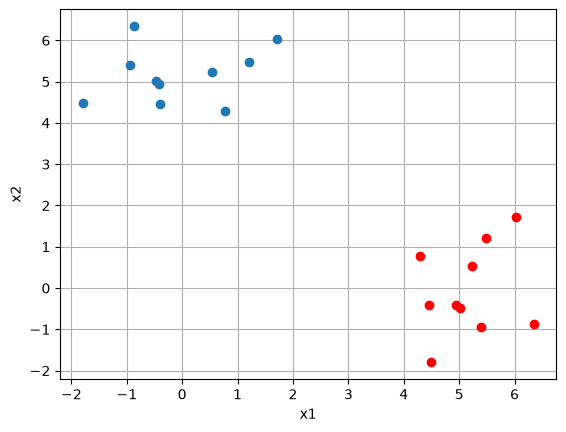

In [100]:
plt.plot(class1_data[:,0], class1_data[:,1], 'o')
plt.plot(class2_data[:,0], class2_data[:,1], 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()

#### Step 2. 모델 만들기

In [ ]:
from torch import nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(2,100)
                                  , nn.Sigmoid()
                                  , nn.Linear(100,1)
                                  , nn.Sigmoid())
    
    def forward(self, x):
        x = self.linear(x)
        return x

In [102]:
model = MLP()
b = model(torch.randn(5,2))
print(b.shape)
print(b)

torch.Size([5, 1])
tensor([[0.5501],
        [0.5451],
        [0.5523],
        [0.5323],
        [0.5441]], grad_fn=<SigmoidBackward0>)


#### Step 3. 모델 학습시키기

In [103]:
from torch import optim

In [104]:
LR = 1e-1
EPOCH = 100

optimizer = optim.SGD(model.parameters(),lr=LR)
criterion = nn.BCELoss()

loss_history = []

model.train() # train mode(학습모드)로 전환
for ep in range(EPOCH):
    # 예측값
    y_hat = model(x)

    # loss
    loss = criterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history += [loss.item()]
    
    # print
    print(f'Epoch : {ep+1} | train loss : {loss.item():.4f}')
    print('-'*20)

Epoch : 1 | train loss : 0.6766
--------------------
Epoch : 2 | train loss : 0.5339
--------------------
Epoch : 3 | train loss : 0.4347
--------------------
Epoch : 4 | train loss : 0.3627
--------------------
Epoch : 5 | train loss : 0.3092
--------------------
Epoch : 6 | train loss : 0.2682
--------------------
Epoch : 7 | train loss : 0.2361
--------------------
Epoch : 8 | train loss : 0.2105
--------------------
Epoch : 9 | train loss : 0.1895
--------------------
Epoch : 10 | train loss : 0.1722
--------------------
Epoch : 11 | train loss : 0.1576
--------------------
Epoch : 12 | train loss : 0.1452
--------------------
Epoch : 13 | train loss : 0.1346
--------------------
Epoch : 14 | train loss : 0.1253
--------------------
Epoch : 15 | train loss : 0.1172
--------------------
Epoch : 16 | train loss : 0.1100
--------------------
Epoch : 17 | train loss : 0.1036
--------------------
Epoch : 18 | train loss : 0.0979
--------------------
Epoch : 19 | train loss : 0.0928
----

Text(0, 0.5, 'Loss')

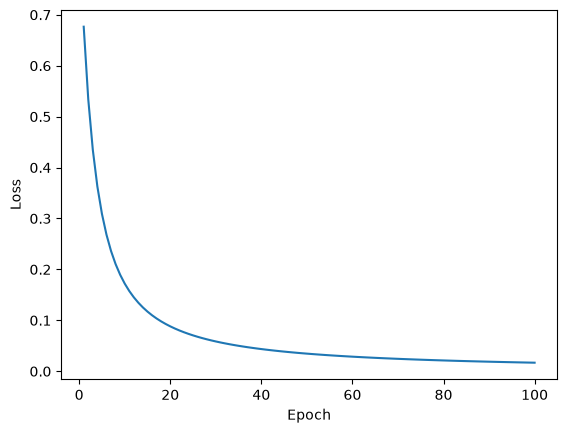

In [105]:
plt.plot(range(1,EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')